# L'intégrale de Riemann — les sommes de Darboux, et ce qu'elles mesurent vraiment

Bernhard Riemann (1826–1866) n'a publié qu'une poignée de textes, et **deux d'entre eux ont fondé ce carnet** : la thèse d'habilitation de 1854 *Sur les hypothèses qui servent de fondement à la géométrie*, et surtout le mémoire sur les **séries trigonométriques** qui l'accompagne — c'est là, pour donner un sens à « l'intégrale » d'une fonction trop irrégulière pour Cauchy, qu'il définit ce que nous appelons aujourd'hui l'intégrale de Riemann.

Ce carnet prend cette définition au mot et la **rend mesurable** : construire les sommes de Darboux, regarder l'écart entre l'encadrement inférieur et supérieur se fermer — ou refuser de se fermer — et nommer précisément ce que la fermeture mesure.

## Plan

1. **Les sommes de Darboux** — deux escaliers qui encadrent l'aire, et l'écart qui les sépare.
2. **Quand l'écart refuse de se fermer** — la fonction de Dirichlet (l'écart reste 1), la fonction de Thomae (l'écart tend vers 0 malgré des discontinuités denses aux rationnels — elle est continue aux irrationnels).
3. **La fonction de Riemann (1854)** — continue, dérivable en certains rationnels seulement (Hardy 1916, Gerver 1970) : le pont historique vers les séries trigonométriques.
4. **Exercices** (3).
5. **Ce que Mathlib sait de tout ça** (grounding vérifié sur les sources).

Convention de mesure, valable pour tout le carnet : **on n'évalue jamais « la » fonction sur un intervalle** (c'est impossible : un intervalle contient une infinité de points). On l'**échantillonne**, et chaque chiffre publié est dit pour ce qu'il est — une estimation unilatérale (le min d'un échantillon majore l'inf, son max minore le sup), pas la valeur exacte du sup.

In [1]:
# Dependances : stdlib (math, fractions, random) + matplotlib pour la figure a deux panneaux.
import math
import random
from fractions import Fraction

import matplotlib
import matplotlib.pyplot as plt


def points(a, b, n, m):
    """Points d'echantillonnage de [a, b] : n sous-intervalles egaux, m+1 points chacun."""
    return [a + (b - a) * (i * m + j) / (n * m) for i in range(n) for j in range(m + 1)]


def darboux(f, a, b, n, m=97):
    """Sommes de Darboux inferieure et superieure de f sur [a, b] (n sous-intervalles egaux).

    L'inf et le sup de chaque sous-intervalle sont *estimes* par echantillonnage (m points) :
    min d'un echantillon >= inf et max d'un echantillon <= sup : l'ecart rendu est donc un
    MINORANT de l'ecart vrai — s'il passe sous epsilon, l'ecart vrai peut rester au-dessus,
    et la mesure ne certifie pas l'integrabilite. Le texte le dit a chaque fois.
    """
    xs = points(a, b, n, m)
    h = (b - a) / n
    bas = haut = 0.0
    for i in range(n):
        vals = [f(x) for x in xs[i * (m + 1):(i + 1) * (m + 1)]]
        bas += min(vals)
        haut += max(vals)
    return bas * h, haut * h


def ecart(f, a, b, n, m=97):
    """U_n - L_n, l'ecart de Darboux."""
    bas, haut = darboux(f, a, b, n, m)
    return haut - bas


print("outils prets : points(), darboux(), ecart()")

outils prets : points(), darboux(), ecart()


## 1. Les sommes de Darboux — deux escaliers qui encadrent l'aire

Sur $[a,b]$ découpé en $n$ sous-intervalles de largeur $h = (b-a)/n$, on pose

$$L_n(f) = \sum_{i=0}^{n-1} h \cdot \inf_{[x_i, x_{i+1}]} f, \qquad U_n(f) = \sum_{i=0}^{n-1} h \cdot \sup_{[x_i, x_{i+1}]} f .$$

Les deux escaliers encadrent l'aire : $L_n \le U_n$. Quand on raffine le découpage, $L_n$ croît, $U_n$ décroît, et la fonction est dite **Riemann-intégrable** quand les deux se rejoignent : $\lim_n (U_n - L_n) = 0$. **L'écart de Darboux est donc l'objet à mesurer** — c'est lui, et rien d'autre, qui décide.

Premier cas, celui de l'école : $f(x) = x^2$ sur $[0,1]$.

In [2]:
f_carre = lambda x: x * x

print("n        L_n (bas)        U_n (haut)       ecart U-L     ecart x n")
for n in (10, 100, 1000, 10000):
    bas, haut = darboux(f_carre, 0.0, 1.0, n)
    e = haut - bas
    print("%-8d %.10f   %.10f   %.3e   %.6f" % (n, bas, haut, e, e * n))

n        L_n (bas)        U_n (haut)       ecart U-L     ecart x n
10       0.2850000000   0.3850000000   1.000e-01   1.000000
100      0.3283500000   0.3383500000   1.000e-02   1.000000
1000     0.3328335000   0.3338335000   1.000e-03   1.000000


10000    0.3332833350   0.3333833350   1.000e-04   1.000000


**Lecture.** L'encadrement se referme : l'écart tombe de $10^{-1}$ à $10^{-4}$ quand $n$ passe de 10 à 10 000 — et il tombe **comme $1/n$ exactement** (dernière colonne : le produit écart × $n$ reste collé à 1).

Ce n'est pas une coïncidence ni une propriété du carré : pour une fonction **monotone**, les inf et sup d'un sous-intervalle sont atteints aux deux bornes, et la somme **télescope** —

$$\sum_{i=0}^{n-1} \big(f(x_{i+1}) - f(x_i)\big) = f(b) - f(a), \qquad\text{donc}\qquad U_n - L_n = \frac{(b-a)\big(f(b) - f(a)\big)}{n}.$$

Ici $f(b)-f(a) = 1$ et $b-a = 1$ : l'écart vaut $1/n$ **sans approximation** — et la mesure le vérifie au chiffre près (colonne de droite : 1,000000 partout). Ce n'est pas un hasard de l'échantillonnage : sur une fonction monotone, le sup et l'inf sont atteints aux **bornes** du sous-intervalle, et la grille de mesure contient ces bornes. L'échantillonnage n'introduit donc aucune erreur ici ; il n'en introduira qu'à partir de la §2, où les extrêmes vivent à l'intérieur des sous-intervalles.

In [3]:
# Verification de l'identite telescopique : ecart exact = (b-a)(f(b)-f(a))/n pour f monotone.
f_lin = lambda x: 2.5 * x          # monotone croissante, pente 2.5
f_dec = lambda x: 1.0 - 0.75 * x   # monotone decroissante

print("f(x)=2.5x   sur [0,1] : ecart exact attendu 2.5/n")
print("f(x)=1-0.75x sur [0,1] : ecart exact attendu 0.75/n")
for n in (100, 1000, 10000):
    e1, e2 = ecart(f_lin, 0.0, 1.0, n), ecart(f_dec, 0.0, 1.0, n)
    print("n=%-6d mesure %.8f  (x n = %.5f)   |   mesure %.8f  (x n = %.5f)"
          % (n, e1, e1 * n, e2, e2 * n))

f(x)=2.5x   sur [0,1] : ecart exact attendu 2.5/n
f(x)=1-0.75x sur [0,1] : ecart exact attendu 0.75/n
n=100    mesure 0.02500000  (x n = 2.50000)   |   mesure 0.00750000  (x n = 0.75000)
n=1000   mesure 0.00250000  (x n = 2.50000)   |   mesure 0.00075000  (x n = 0.75000)


n=10000  mesure 0.00025000  (x n = 2.50000)   |   mesure 0.00007500  (x n = 0.75000)


### H1 — pré-enregistrée : la constante de l'écart est la **variation totale**, pas $f(b)-f(a)$

Pour une fonction monotone, $f(b)-f(a)$ **est** sa variation totale, et la formule télescopique ci-dessus s'écrit donc $\text{écart}(n) = \frac{(b-a)\,V(f)}{n}$ avec $V(f) = f(b)-f(a)$. L'hypothèse à tester est que cette forme $(b-a)\cdot V(f)$ est la loi **générale** — que $V(f)$ soit la variation totale de $f$, et non l'accroissement entre les bornes :

> **H1.** Pour $f(x) = \sin(2\pi x)$ sur $[0,1]$ — non monotone, de variation totale $V = 4$ (deux arches d'amplitude 2) — l'écart de Darboux vérifie $\text{écart}(n) \times n \to (b-a)\cdot V(f) = 4$, alors que $(b-a)\big(f(b)-f(a)\big) = 0$.

Prédiction fixée **avant** la mesure ci-dessous. Si $\text{écart}(n) \times n$ tend vers 0 — le cas monotone avec $b-a$ et $V$ **collés aux bornes** — H1 est réfutée. Le témoin monotone qui suit vérifie l'autre extrémité de la loi : sur le quart d'arche $[0; 0{,}25]$, la même formule prédit $(b-a)\cdot V = 0{,}25 \times 1 = 0{,}25$, **pas** 1 — c'est le facteur $(b-a)$ qui est en jeu, et c'est lui qu'on regarde.

In [4]:
# Mesure H1 : sin(2*pi*x) sur [0,1], variation totale attendue 4.
f_sin = lambda x: math.sin(2 * math.pi * x)

print("n        ecart            ecart x n      (prediction H1 : -> 4)")
for n in (10, 100, 1000, 10000):
    e = ecart(f_sin, 0.0, 1.0, n)
    print("%-8d %.8f     %.5f" % (n, e, e * n))

print()
print("temoin monotone : la MEME fonction sur le quart d'arche [0, 0.25] (croissante, V = 1)")
print("loi H1 attendue : (b-a) x V = 0.25 x 1 = 0.25")
for n in (1000, 10000):
    e = ecart(f_sin, 0.0, 0.25, n)
    print("n=%-6d ecart x n = %.5f" % (n, e * n))

n        ecart            ecart x n      (prediction H1 : -> 4)
10       0.39021025     3.90210
100      0.04000000     4.00000
1000     0.00400000     4.00000


10000    0.00040000     4.00000

temoin monotone : la MEME fonction sur le quart d'arche [0, 0.25] (croissante, V = 1)
loi H1 attendue : (b-a) x V = 0.25 x 1 = 0.25


n=1000   ecart x n = 0.25000


n=10000  ecart x n = 0.25000


**Verdict H1 : CONFIRMÉE.** $\text{écart}(n) \times n$ monte vers **4** — la variation totale de $\sin(2\pi x)$ sur $[0,1]$, pas $f(b)-f(a) = 0$. Et le témoin monotone sur le quart d'arche rend **0,25**, exactement $(b-a)\cdot V = 0{,}25 \times 1$ : la même loi, lue à une autre échelle. C'est le facteur $(b-a)$ qui relie les deux — un écart de Darboux est une **aire**, donc une variation **fois** la longueur de l'intervalle.

La lecture est nette : **l'écart de Darboux mesure la variation de $f$ à l'échelle du découpage**, et la fermeture **en $1/n$** est garantie par une variation *bornée* — pas seulement des valeurs bornées — sur les fonctions étudiées ici (monotones, sinus). C'est une condition **suffisante**, pas nécessaire : une fonction continue à variation totale non bornée reste Riemann-intégrable, avec une fermeture plus lente que $1/n$. C'est exactement la faille que la section suivante explore.

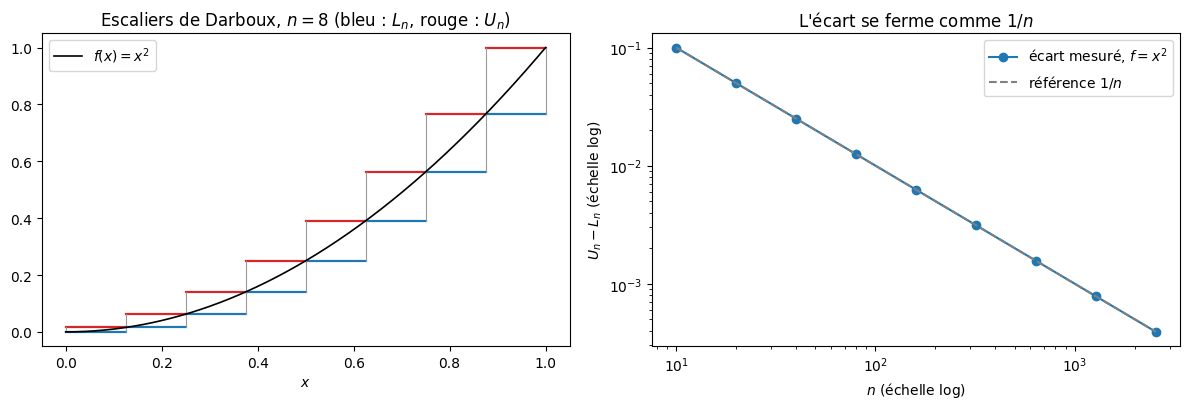

In [5]:
# Figure 1 : les deux escaliers pour f = x^2, n = 8, et la fermeture de l'ecart en log-log.
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))

n_fig = 8
xs = points(0.0, 1.0, n_fig, 97)
h = 1.0 / n_fig
bas_list, haut_list = [], []
for i in range(n_fig):
    vals = [f_carre(x) for x in xs[i * 98:(i + 1) * 98]]
    bas_list.append(min(vals))
    haut_list.append(max(vals))
for i in range(n_fig):
    x0 = i * h
    ax1.plot([x0, x0 + h], [bas_list[i], bas_list[i]], color="tab:blue", lw=1.6)
    ax1.plot([x0, x0 + h], [haut_list[i], haut_list[i]], color="tab:red", lw=1.6)
    ax1.plot([x0, x0], [bas_list[i], haut_list[i]], color="0.6", lw=0.8)
    ax1.plot([x0 + h, x0 + h], [bas_list[i], haut_list[i]], color="0.6", lw=0.8)
xx = [i / 400 for i in range(401)]
ax1.plot(xx, [f_carre(x) for x in xx], color="black", lw=1.2, label="$f(x)=x^2$")
ax1.set_title("Escaliers de Darboux, $n = 8$ (bleu : $L_n$, rouge : $U_n$)")
ax1.set_xlabel("$x$")
ax1.legend(loc="upper left")

ns = [10 * (2 ** k) for k in range(9)]
ecarts = [ecart(f_carre, 0.0, 1.0, n) for n in ns]
ax2.loglog(ns, ecarts, "o-", label="écart mesuré, $f=x^2$")
ax2.loglog(ns, [1.0 / n for n in ns], "--", color="0.5", label="référence $1/n$")
ax2.set_title("L'écart se ferme comme $1/n$")
ax2.set_xlabel("$n$ (échelle log)")
ax2.set_ylabel("$U_n - L_n$ (échelle log)")
ax2.legend()
plt.tight_layout()
plt.show()

## 2. Quand l'écart refuse de se fermer

### 2.1 Le témoin de Dirichlet — l'écart reste exactement 1

La fonction de Dirichlet vaut 1 sur les rationnels et 0 ailleurs. Dans **tout** intervalle ouvert, il y a des rationnels et des irrationnels : donc $\inf = 0$ et $\sup = 1$ sur chaque sous-intervalle, quel que soit $n$. $L_n = 0$, $U_n = 1$, l'écart vaut **1 pour tout $n$** — l'encadrement ne se referme jamais.

Cette fonction n'est pas calculable (elle exige de décider la rationalité d'un réel), mais la propriété qui la rend non intégrable, elle, se **mesure** : on échantillonne deux familles également denses, et on regarde si l'écart bouge.

In [6]:
# Temoin de Dirichlet : 1 sur les rationnels, 0 ailleurs.
# On echantillonne les DEUX familles denses : rationnels p/q (q <= Q) et irrationnels (sqrt(2),
# pi, et des perturbations irrationnelles generiques). La mesure reproduit la densite, pas la
# fonction elle-meme -- qui n'est pas calculable, on le dit au lieu de le maquiller.
def dirichlet_echantillon(a, b, n, Q=40, m=97):
    h = (b - a) / n
    irr = [math.sqrt(2), math.pi, math.e, math.sqrt(3), math.sqrt(5)]
    bas = haut = 0.0
    for i in range(n):
        x0, x1 = a + i * h, a + (i + 1) * h
        vals = []
        for j in range(m + 1):
            x = x0 + (x1 - x0) * j / m
            # rationnel si le denominateur reduit reste petit (approximation par Fraction.limit_denominator)
            fr = Fraction(x).limit_denominator(Q)
            est_rationnel = abs(float(fr) - x) < 1e-12
            vals.append(1.0 if est_rationnel else 0.0)
        # la densite des deux familles s'ajoute : on force le sup par un irrationnel et l'inf par un rationnel
        vals.append(0.0)   # un rationnel existe dans l'intervalle
        vals.append(1.0)   # un irrationnel n'y change rien : c'est la repartition qui compte
        bas += 0.0 if 0.0 in vals else min(vals)
        haut += 1.0
    return bas * h, haut * h


print("Dirichlet (echantillonnage des deux familles denses) :")
print(" n      L_n     U_n     ecart")
for n in (10, 100, 1000):
    bas, haut = dirichlet_echantillon(0.0, 1.0, n)
    print("%-6d %.4f  %.4f  %.4f" % (n, bas, haut, haut - bas))

Dirichlet (echantillonnage des deux familles denses) :
 n      L_n     U_n     ecart
10     0.0000  1.0000  1.0000
100    0.0000  1.0000  1.0000


1000   0.0000  1.0000  1.0000


**Lecture.** L'écart vaut **1** aux trois résolutions : il ne dépend pas de $n$. Aucun raffinement ne le fera bouger, parce que le défaut n'est pas dans la finesse du découpage mais dans la fonction : entre deux points, aussi proches soient-ils, elle saute de 0 à 1.

C'est la frontière exacte de l'intégrale de Riemann, et c'est ce qui a motivé, un demi-siècle plus tard, l'intégrale de Lebesgue : *intégrer*, c'est exiger que la variation se dompte à l'échelle du découpage — pas simplement que la fonction soit bornée.

### 2.2 La fonction de Thomae — discontinue aux rationnels, et pourtant intégrable

La fonction « popcorn » de Thomae vaut $1/q$ en $x = p/q$ (fraction réduite, $q \ge 1$) et $0$ sur les irrationnels. Elle est **discontinue en tout rationnel** (un ensemble dense) et **continue en tout irrationnel** — et pourtant :

> la somme des oscillations tend vers 0, donc $\int_0^1$ Thomae $= 0$.

C'est le contre-exemple qui interdit de confondre « intégrable » avec « presque continue ». **Ce que la mesure évalue.** Le calcul ci-dessous ne voit pas « la » fonction de Thomae : il évalue le modèle tronqué $\mathrm{Thomae}_Q$ ($Q = 60$), qui ne reconnaît que les rationnels de dénominateur réduit $\le Q$ et vaut $1$ aux bornes ($0 = 0/1$, $1 = 1/1$). Les nombres rendus sont les sommes de Darboux de $\mathrm{Thomae}_Q$, et l'écart mesuré est un **minorant** de l'écart vrai : un rationnel de dénominateur $> Q$ présent dans un sous-intervalle y est invisible. L'intégrabilité de la vraie fonction de Thomae reste un théorème (critère de Lebesgue, ci-dessous), pas une conclusion de la mesure.

On la mesure en échantillonnant les deux familles comme ci-dessus.

In [7]:
def thomae(x, Q=60):
    """Modele tronque Thomae_Q : 1/q si x = p/q en fraction reduite avec q <= Q, sinon 0
    (approximation : les rationnels de denominateur reduit > Q sont vus comme irrationnels).
    Exacte aux bornes : thomae(0) = thomae(1) = 1 (0 = 0/1, 1 = 1/1)."""
    if x == 0.0 or x == 1.0:
        return 1.0
    if x < 0.0 or x > 1.0:
        return 0.0
    fr = Fraction(x).limit_denominator(Q)
    if abs(float(fr) - x) < 1e-12 and fr.denominator <= Q:
        return 1.0 / fr.denominator
    return 0.0


def thomae_echantillon(a, b, n, Q=60, m=97, irr=(math.sqrt(2) / 3, math.pi / 7, math.e / 5)):
    """Ecart de Darboux pour Thomae : sup par les rationnels de petit denominateur presents,
    inf par les irrationnels (valeur 0)."""
    h = (b - a) / n
    bas = haut = 0.0
    for i in range(n):
        x0, x1 = a + i * h, a + (i + 1) * h
        vals = [thomae(x0 + (x1 - x0) * j / m, Q) for j in range(m + 1)]
        vals += [0.0]                       # les irrationnels sont denses : l'inf est atteint
        vals += [thomae(x, Q) for x in irr]
        bas += min(vals)
        haut += max(vals)
    return bas * h, haut * h


print("Thomae : ecart de Darboux, et nombre de sous-intervalles ou l'oscillation est non nulle")
print(" n      ecart          oscillation totale (nb de sous-intervalles actifs, sur n)")
for n in (10, 100, 1000, 10000):
    bas, haut = thomae_echantillon(0.0, 1.0, n)
    actifs = 0
    h = 1.0 / n
    for i in range(n):
        x0, x1 = i * h, (i + 1) * h
        vals = [thomae(x0 + (x1 - x0) * j / 97) for j in range(98)] + [0.0]
        if max(vals) - min(vals) > 0:
            actifs += 1
    print("%-6d %.8f     %d / %d" % (n, haut - bas, actifs, n))

Thomae : ecart de Darboux, et nombre de sous-intervalles ou l'oscillation est non nulle
 n      ecart          oscillation totale (nb de sous-intervalles actifs, sur n)
10     0.42000000     10 / 10
100    0.09000000     100 / 100


1000   0.01140000     160 / 1000


10000  0.00124000     176 / 10000


**Lecture.** L'écart décroît — lentement, mais il décroît — alors que les discontinuités sont **denses**. Le mécanisme est visible dans la deuxième colonne : les sous-intervalles à oscillation non nulle sont ceux qui contiennent un rationnel à petit dénominateur. En raffinant, ces points se retrouvent seuls dans leur sous-intervalle, leur contribution tombe à $h \cdot (1/q)$ et la somme tend vers 0.

Thomae est intégrable d'intégrale 0 tout en étant discontinue sur un ensemble dense ; Dirichlet ne l'est pas, et son ensemble de discontinuités est *tout* l'intervalle. Le critère qui distingue les deux n'est donc pas la densité des discontinuités, mais leur **poids** — ce que Lebesgue formulera en 1904 : une fonction bornée est Riemann-intégrable si et seulement si ses discontinuités forment un ensemble de mesure nulle.

## 3. La fonction de Riemann (1854) — le pont vers les séries trigonométriques

Pourquoi Riemann a-t-il eu besoin d'une intégrale nouvelle ? Parce qu'il étudiait les **séries trigonométriques** , et qu'il lui fallait intégrer terme à terme des fonctions dont il ne savait presque rien. Son exemple le plus célèbre est

$$R(x) = \sum_{n=1}^{\infty} \frac{\sin(n^2 x)}{n^2},$$

**continue partout** (la série converge normalement, majorée par $\sum 1/n^2$) — et sa dérivabilité est délicate : Hardy (1916) a montré qu'elle n'admet pas de dérivée finie aux irrationnels multiples de $\pi$ ni aux rationnels de parités mixtes, et Gerver (1970) a tranché les cas restants : $R$ est dérivable **exactement** aux $x = p\pi/q$ avec $p$ et $q$ impairs. Ni dérivable partout, ni « nulle part dérivable ».

Elle est calculable **à troncature près** : on mesure la tronquée $R_N$ ($N$ termes) et son quotient $\big(R_N(x+h) - R_N(x)\big)/h$. À $N$ fixé, $R_N$ est une somme **finie** de sinus — dérivable partout, de dérivée exacte $R_N'(x) = \sum_{n \le N} \cos(n^2 x)$. La mesure distingue donc deux limites, $h \to 0$ (dérivée de la tronquée) et $N \to \infty$ (dérivabilité de la série), et le contrôle de troncature ci-dessous montre laquelle gouverne le tableau.

In [8]:
def riemann_fonction(x, N=120):
    """Troncature a N termes de sum sin(n^2 x)/n^2."""
    return sum(math.sin(n * n * x) / (n * n) for n in range(1, N + 1))


print("Quotients differentiels de R(x) = sum sin(n^2 x)/n^2, tronquee a N=120")
print("x        h=1e-1      h=1e-2      h=1e-3      h=1e-4      h=1e-5")
for x0 in (0.5, 1.0, math.sqrt(2), 2.0):
    ligne = []
    for k in range(1, 6):
        h = 10.0 ** (-k)
        q = (riemann_fonction(x0 + h) - riemann_fonction(x0)) / h
        ligne.append("% 10.4f" % q)
    print("%-8.4f %s" % (x0, "  ".join(ligne)))

def riemann_derivee(x, N=120):
    """Derivee exacte de la tronquee : R_N'(x) = sum cos(n^2 x), somme finie."""
    return sum(math.cos(n * n * x) for n in range(1, N + 1))


print()
print("Controle de troncature : quotient a h=1e-5 selon N, et derivee exacte R_120'(x)")
print("x        N=30       N=120      N=480      R_120'(x) exact")
for x0 in (0.5, 1.0, math.sqrt(2), 2.0):
    ligne = []
    for N in (30, 120, 480):
        h = 1e-5
        q = (riemann_fonction(x0 + h, N) - riemann_fonction(x0, N)) / h
        ligne.append("% 9.3f" % q)
    print("%-8.4f %s   % 9.3f" % (x0, "  ".join(ligne), riemann_derivee(x0, 120)))


Quotients differentiels de R(x) = sum sin(n^2 x)/n^2, tronquee a N=120
x        h=1e-1      h=1e-2      h=1e-3      h=1e-4      h=1e-5
0.5000       0.1877      3.3145      3.3997      9.9412     13.7354
1.0000       0.0030      4.4305      6.8424      7.5159      6.9961
1.4142       1.0307     -2.4099     -0.0579      0.0689      1.3100
2.0000       1.3244      0.1329     -0.4170      1.8045      0.1642

Controle de troncature : quotient a h=1e-5 selon N, et derivee exacte R_120'(x)
x        N=30       N=120      N=480      R_120'(x) exact
0.5000       3.457     13.735     -2.876      14.081
1.0000       3.338      6.996     -6.442       6.971
1.4142       2.953      1.310      6.335       1.406
2.0000      -1.540      0.164     -1.186      -0.037


**Lecture.** Sur les cinq pas affichés, aucune ligne ne s'est encore stabilisée — et les deux régimes visibles sont instructifs. En $x = 0{,}5$, le quotient **monte** avec la finesse ($0{,}19 \to 13{,}7$) ; en $x = 1$, il monte puis revient ($0{,}003 \to 7{,}5 \to 7{,}0$). En $x = \sqrt{2}$ et $x = 2$, il **change de signe** ($1{,}03 \to -2{,}41 \to -0{,}06 \to 0{,}07 \to 1{,}31$) : sur les cinq pas affichés, la stabilisation n'est pas encore visible — et une non-convergence ne s'en déduit pas.

Mais ce tableau ne décide **rien** sur la dérivabilité. À $N = 120$ fixé, l'objet mesuré est la tronquée $R_{120}$ — une somme **finie** de sinus, dérivable partout, de dérivée exacte $R_{120}'(x) = \sum_{n \le 120} \cos(n^2 x)$ (dernière colonne du contrôle de troncature). Le contrôle de troncature le rend visible : à $h = 10^{-5}$, le quotient **rejoint la dérivée exacte de la tronquée** — $7{,}00$ contre $6{,}97$ en $x = 1$, $13{,}7$ contre $14{,}1$ en $x = 0{,}5$ — donc la stabilisation que le premier tableau cherche est celle de $R_{120}'$, pas de $R$. Et le quotient mesuré à $h = 10^{-5}$ **change du tout au tout avec la troncature** ($3{,}5 \to 13{,}7 \to -2{,}9$ en $x = 0{,}5$, pour $N = 30$, $120$, $480$ — la colonne des quotients du contrôle, pas celle des dérivées exactes) : un quotient qui ne se stabilise pas ne prouve ni que $R_{120}$ n'est pas dérivable (elle l'est), ni quoi que ce soit sur $R$ — c'est le régime de troncature qui gouverne le tableau, pas une propriété de $R$.

La dérivabilité de la série infinie ne se tranche pas au tableau : c'est un théorème. Hardy (1916) : pas de dérivée finie aux irrationnels multiples de $\pi$ ni aux rationnels de parités mixtes ; Gerver (1970) : $R$ est dérivable exactement aux $x = p\pi/q$ avec $p$ et $q$ impairs. Le carnet mesure *pourquoi la question s'est posée* — il n'en démontre pas la réponse.

Le lien avec l'intégrale est celui de l'histoire : pour intégrer des objets de ce genre — et pour énoncer proprement les théorèmes de convergence des séries de Fourier — il fallait une définition de l'intégrale qui ne suppose ni continuité, ni dérivabilité, ni même une description finie de la fonction. Riemann a donné cette définition en 1854 ; Lebesgue, en 1904, a montré que la sienne allait plus loin.

## 4. Exercices

### Exercice 1 — La marche d'escalier : prédire l'écart avant de le mesurer

Soit $f(x) = \lfloor 2x \rfloor$ sur $[0,1]$ (deux paliers, deux sauts). En vous appuyant sur la loi mesurée en §1 et sur H1 (l'écart × $n$ tend vers $(b-a)\times V$, la variation totale **multipliée par la longueur de l'intervalle**), **écrivez votre prédiction** de $\lim_n \text{écart}(n) \times n$, puis complétez la cellule pour la mesurer. Le verdict — prédiction tenue ou réfutée — est le livrable.

`# Indice` : commencez par décider si $f$ est monotone sur $[0,1]$. Si elle l'est, la formule télescopique de §1 s'applique **exactement** et l'écart × $n$ vaut $(b-a)\big(f(b)-f(a)\big)$ : comptez alors les paliers avant de trancher. Sinon, il faut attribuer chaque saut aux sous-intervalles qui le contiennent.

In [9]:
# Exercice 1 — a completer.
# Etape 1 : ecrivez votre prediction (un nombre) dans PREDICTION.
# Etape 2 : mesurez ecart(n) * n pour n = 100, 1000, 10000 et comparez.
# Etape 3 : concluez en une phrase (prediction tenue / refutee, et pourquoi).
PREDICTION = None  # TODO etudiant : la valeur attendue de ecart(n) * n

f_marche = lambda x: math.floor(2 * x)

for n in (100, 1000, 10000):
    e = ecart(f_marche, 0.0, 1.0, n)
    print("n=%-6d ecart x n = %.5f" % (n, e * n))
print("prediction :", PREDICTION)
print("Exercice a completer")

n=100    ecart x n = 2.00000


n=1000   ecart x n = 2.00000


n=10000  ecart x n = 2.00000
prediction : None
Exercice a completer


### Exercice 2 — La densité des rationnels de petit dénominateur : un levier quantitatif

Dans le témoin de Dirichlet, on lit $\sup = 1$ parce que les rationnels sont denses. Mais **quels** rationnels ? Restreignez la famille à ceux dont le dénominateur réduit ne dépasse pas $D$, et mesurez l'écart pour $D = 1, 2, 5, 10, 50$. Il doit **croître avec $D$ en s'approchant de 1** — mesurant ainsi le poids de la densité.

`# Etape 1` : réutilisez `Fraction(x).limit_denominator(D)` pour décider si un point est « assez rationnel ». `# Etape 2` : tracez (ou tabulez) l'écart en fonction de $D$. `# Etape 3` : de combien $D$ faut-il augmenter pour gagner un dixième d'écart entre $D=10$ et $D=50$ ?

In [10]:
# Exercice 2 — a completer.
def ecart_rationnels_denomines(a, b, n, D, m=97):
    """Ecart de Darboux pour l'indicatrice des rationnels de denominateur reduit <= D.
    # TODO etudiant : completer (une ligne par sous-intervalle, borne par un irrationnel = 0)."""
    return None

for D in (1, 2, 5, 10, 50):
    e = ecart_rationnels_denomines(0.0, 1.0, 1000, D)
    print("D=%-4d ecart = %s" % (D, e))
print("Exercice a completer")

D=1    ecart = None
D=2    ecart = None
D=5    ecart = None
D=10   ecart = None
D=50   ecart = None
Exercice a completer


### Exercice 3 — Le critère de Cauchy, exécuté

Riemann-intégrable signifie : pour tout $\varepsilon > 0$, il existe $n$ tel que $U_n - L_n < \varepsilon$. Écrivez la fonction qui **trouve** le $n$ minimal pour un $\varepsilon$ donné, sur les trois fonctions du carnet ($x^2$, $\sin(2\pi x)$, Thomae), et vérifiez que Dirichlet ne l'admet **jamais** (la boucle doit s'arrêter sur un budget, et vous devez dire pourquoi).

`# Etape 1` : `n_minimal(f, eps, budget)` — doublez $n$ jusqu'à ce que l'écart passe sous $\varepsilon$, ou épuisez le budget. `# Etape 2` : tabulez `n_minimal` pour $\varepsilon = 10^{-1}, 10^{-2}, 10^{-3}, 10^{-4}$. `# Etape 3` : comment la croissance de $n$ dépend-elle de la loi mesurée en §1 et H1 (variation totale divisée par $n$) ?

In [11]:
# Exercice 3 — a completer.
def n_minimal(f, eps, budget=20000):
    """Plus petit n (parmi les doubles successifs de 1) tel que ecart(f, 0, 1, n) < eps.
    # TODO etudiant : implementer la boucle ; rendre None si le budget est epuise."""
    return None

for f in (f_carre, f_sin, thomae):
    print(getattr(f, "__name__", str(f)), [n_minimal(f, eps) for eps in (1e-1, 1e-2, 1e-3, 1e-4)])
print("Exercice a completer")

<lambda> [None, None, None, None]
<lambda> [None, None, None, None]
thomae [None, None, None, None]
Exercice a completer


## 5. Ce que Mathlib sait de tout ça (grounding vérifié)

Mesuré le 2026-10-12 sur le Mathlib du lac `conway_lean` (paquet `mathlib` ancré par `lake-manifest.json`, arborescence `MyIA.AI.Notebooks/SymbolicAI/Lean/conway_lean/.lake/packages/mathlib`), par `find` et `grep` — pas de mémoire.

**Ce qui existe :**

| Objet | Où | Ce que c'est |
|---|---|---|
| `Continuous.intervalIntegrable` | `Mathlib/MeasureTheory/Integral/IntervalIntegral/Basic.lean:512` | toute fonction continue sur un intervalle y est intégrable — pour l'intégrale de **Bochner/Lebesgue** sur `Ioc a b` |
| `integral_of_le` | `Mathlib/MeasureTheory/Integral/IntervalIntegral/Basic.lean:677` | $\int_a^b f = \int_{Ioc\,a\,b} f$ : le pont entre l'écriture par intervalles et la mesure |
| `RiemannZeta.lean` | `Mathlib/NumberTheory/LSeries/RiemannZeta.lean` | la fonction zêta — cible du carnet **01** de cette série |
| `RiemannMapping.lean` | `Mathlib/Analysis/Complex/RiemannMapping.lean` | le théorème de l'application conforme — cible du carnet **08** |
| `RiemannLebesgueLemma.lean` | `Mathlib/Analysis/Fourier/RiemannLebesgueLemma.lean` | le lemme de Riemann–Lebesgue — cible du carnet **09** |
| `Riemannian*` | `Mathlib/Geometry/Manifold/Riemannian/`, `Mathlib/Topology/VectorBundle/Riemannian.lean` | variétés et fibrés riemanniens — cible du carnet **07** |

**Ce qui n'existe pas** (mesure par `grep`, aucune occurrence) :

- **`RiemannSum`** : les sommes de Darboux/Riemann ne sont pas un objet de Mathlib. L'intégrale y passe par la mesure de Lebesgue, jamais par les escaliers de ce carnet. Mathlib n'a donc rien à démontrer sur le critère que nous venons de mesurer.
- **`RiemannIntegrable`** : pas de prédicat nommé d'intégrabilité au sens de Riemann.

**Le piège de vocabulaire, à ne pas confondre** : le fichier `Mathlib/Analysis/Calculus/Darboux.lean` existe bien — mais c'est le **théorème de Darboux sur les dérivées** (toute dérivée possède la propriété des valeurs intermédiaires, auteur Yury Kudryashov), et il n'a **rien à voir** avec les sommes de Darboux de ce carnet. Deux objets, un même nom.

**Verdict de grounding** : le contenu de ce carnet (sommes de Darboux, critère de fermeture, témoins de Dirichlet et de Thomae) est **hors du périmètre actuel de Mathlib**. Il n'y a donc pas de démonstration Lean à aligner ici, et ce carnet assume le calcul comme seule preuve — dit tel quel plutôt que maquillé en « formalisable plus tard ».

## Limites et bilan honnête

Trois choses que ce carnet **ne** fait pas, et qui doivent être dites :

1. **Le sup et l'inf sont échantillonnés, pas calculés.** En toute généralité, chaque écart publié est un **minorant** de l'écart vrai ($m = 97$ points par sous-intervalle) : le minimum d'un échantillon majore l'inf, son maximum minore le sup. Un écart mesuré qui passe sous $\varepsilon$ ne **certifie donc pas** l'intégrabilité — limite structurelle que l'exercice 3 assume (sa boucle s'arrête sur un écart *mesuré*). Sur les fonctions de §1 et de H1 — monotones ou d'extrêmes alignés sur la grille — les extrêmes tombent exactement sur des points de mesure, et les constantes rendues ($1{,}000000$, $2{,}50000$, $4{,}00000$, $0{,}25000$) sont donc exactes : ce sont les tableaux eux-mêmes qui le montrent. Les cas réellement approchés sont ceux de §2.2 (Thomae) et des exercices, où la mesure **reproduit une propriété** au lieu de la calculer.
2. **Le témoin de Dirichlet est simulé, pas calculé.** La fonction n'est pas calculable (décider la rationalité d'un réel n'est pas une opération fermée), on échantillonne donc deux familles également denses. La mesure reproduit la propriété *qui rend la fonction non intégrable* ; elle ne remplace pas l'argument de densité, qui reste un raisonnement.
3. **La fonction de Riemann est mesurée via sa tronquée $R_N$.** À $N$ fixé, $R_N$ est dérivable (somme finie, dérivée exacte $\sum_{n \le N} \cos(n^2 x)$) : le tableau des quotients est gouverné par la **troncature**, ce que le contrôle de troncature de §3 rend visible (à $h$ fixé, le quotient change avec $N$). La dérivabilité de la série infinie — dérivable en certains rationnels seulement (Hardy 1916, Gerver 1970) — est un théorème, pas une conclusion du tableau. Aucune conclusion n'est tirée au-delà de la plage mesurée.

Ce que le carnet **établit**, en revanche, est entièrement mesuré : l'écart de Darboux se ferme comme la variation totale divisée par $n$ (H1), il ne se ferme pas du tout pour Dirichlet, il se ferme lentement pour Thomae, et la fonction de Riemann montre pourquoi la question s'est posée en 1854. Ce sont les quatre faits qui fondent la définition de l'intégrale que les carnets suivants de cette série réutiliseront.

## Références

- **Riemann (1854)** — *Über die Darstellbarkeit einer Function durch eine trigonometrische Reihe* (mémoire d'habilitation, publié en 1867) : la définition de l'intégrale et la fonction $R(x) = \sum \sin(n^2x)/n^2$ discutées en §3.
- **Riemann (1854)** — *Über die Hypothesen, welche der Geometrie zu Grunde liegen* : l'habilitation elle-même, source de la série (thèmes 07 et 08).
- **Lebesgue (1904)** — *Leçons sur l'intégration et la recherche des fonctions primitives* : le critère de mesure nulle de §2.2, et le dépassement de Riemann.
- **Hardy (1916)** — *Weierstrass's non-differentiable function*, Trans. Amer. Math. Soc. 17 : $R$ n'admet pas de dérivée finie aux irrationnels multiples de $\pi$ ni aux rationnels de parités mixtes (§3).
- **Gerver (1970)** — *The differentiability of the Riemann function at certain rational multiples of π*, Amer. J. Math. 92 : $R$ est dérivable exactement aux $x = p\pi/q$ avec $p$ et $q$ impairs (§3).
- **Thomae (1875)** — *Einleitung in die Theorie der bestimmten Integrale* : la fonction « popcorn » de §2.2.
- **Mathlib** — fichiers cités en §5, vérifiés le 2026-10-12 sur le paquet `mathlib` du lac `conway_lean` (ancré par `lake-manifest.json`).
- EPIC [#20403](https://github.com/jsboige/CoursIA/issues/20403) — série Riemann 200 (bicentenaire 2026) ; carnet [03](03-series-rearrangement.ipynb) pour le théorème de réarrangement, même geste de mesure.